# 3. Persistent Homology Analysis
## Blue/Green Gecko / Model Training
### Mia-Katrin Kvalsund
### April 2026


Code to support ALIFE 2026 paper:
 > Stovold, Kvalsund, Ludwig, Sharma, Mordvintsev "Visualising the Attractor Landscape of Neural Cellular Automata"

Based on the Colab notebook developed by Mordvintsev et al. for the ["Growing Neural Cellular Automata"](http://distill.pub/2020/growing-ca) article. and J. Stovold's notebook for the ["Neural Cellular Automata can Respond to Signals"](https://github.com/jstovold/ALIFE2023/blob/master/ExternalSignals.ipynb) article at ALIFE 2023.

Code and materials are restricted for any and all use prior to publication; post-publication the code and associated materials are available under the Apache 2.0 license


In [1]:
import numpy as np
import torch

# Plotting 
import matplotlib.pyplot as plt

# Persistent homology
from ripser import ripser
from persim import plot_diagrams
import gudhi as gd

# Dimensionality reduction
from sklearn.decomposition import PCA

### Load and reshape data: 18 GB loaded

In [2]:
data = torch.from_numpy(np.load("data/xx_4models.npy"))

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0703442..1.0671661].


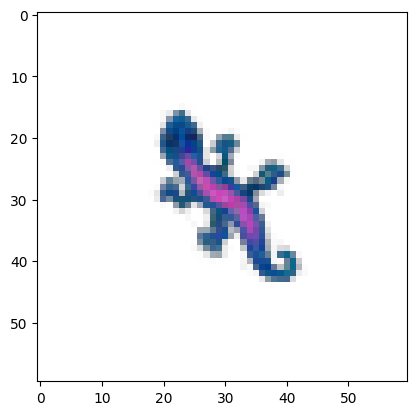

In [3]:
# Permute to tensorflow shape for later plotting and color calculations
E, H, W, C, T = data.shape # James' shape with timesteps at the end
data_3D = data.permute(0, 4, 1, 2, 3) # Creates a view, does not bog down memory

# Check that it looks okay after permuting
plt.imshow(data_3D[0, np.random.randint(0, data_3D.shape[1])].numpy()[:,:,:4])

In [4]:
# Combine the substrate vector
data_total = data_3D.reshape(E, T, H * W * C)

n = min(600, data_total.shape[1])
idx = np.arange(n) #np.random.randint(0, data_total.shape[0], n)
data = data_total[:,idx] # Makes new vector, but small, doesn't add much to memory

print("New data is now shape", data.shape)

New data is now shape torch.Size([4, 600, 61200])


In [5]:
# We assume the highest dimension hole will be a 3D hole, so maxdim is 2
diagrams_list = []
for i in range(E):
    diagrams = ripser(data[i], maxdim=2, metric="euclidean")['dgms']
    diagrams_list.append(diagrams)


/Users/mkkvalsu/Desktop/work/testing_ground/alice_paper/.venv/lib/python3.11/site-packages/ripser/ripser.py:257: UserWarning: The input point cloud has more columns than rows; did you mean to transpose?
  warnings.warn(
/Users/mkkvalsu/Desktop/work/testing_ground/alice_paper/.venv/lib/python3.11/site-packages/ripser/ripser.py:257: UserWarning: The input point cloud has more columns than rows; did you mean to transpose?
  warnings.warn(
/Users/mkkvalsu/Desktop/work/testing_ground/alice_paper/.venv/lib/python3.11/site-packages/ripser/ripser.py:257: UserWarning: The input point cloud has more columns than rows; did you mean to transpose?
  warnings.warn(
/Users/mkkvalsu/Desktop/work/testing_ground/alice_paper/.venv/lib/python3.11/site-packages/ripser/ripser.py:257: UserWarning: The input point cloud has more columns than rows; did you mean to transpose?
  warnings.warn(


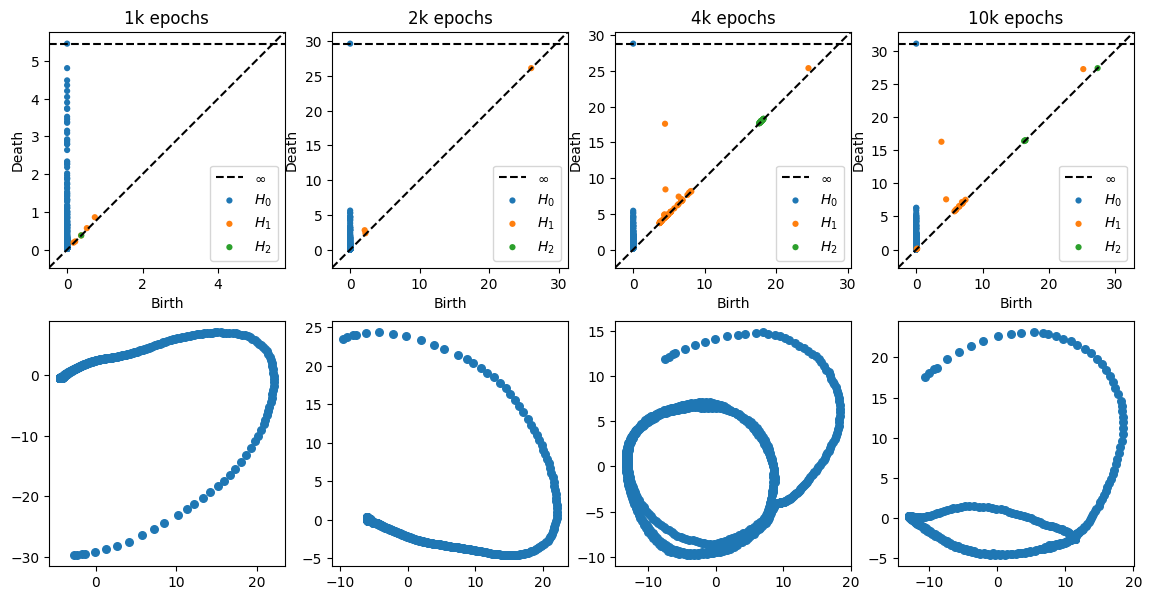

In [6]:
fig, ax_list = plt.subplots(2, 4, figsize=(14, 7))
titles = ["1k", "2k", "4k", "10k"]

for i in range(E):
    ax_list[0][i].set_title(titles[i]+" epochs")
    plot_diagrams(diagrams_list[i], ax=ax_list[0][i])

    X2 = PCA(n_components=2).fit_transform(data[i])

    ax_list[1][i].scatter(X2[:,0], X2[:,1], s=30)